# Coal stockpile — volume through time
A bunded pad of black material (coal / coal rejects) next to the preparation plant of an open-cut mine. Name and location are masked on purpose — maps use km from the site.

| source | what it measures | period |
|---|---|---|
| SRTM, ALOS AW3D30, Copernicus DEM | stockpile **height** above the ground it was built on | 2000, ~2008, ~2012 |
| Sentinel-1 RTC | **height change** from the geocoding shift (radargrammetry) | quarterly since 2016Q3 |
| Sentinel-2 L2A | **footprint** of black material and water, texture for 3D | quarterly since 2016Q3 |

In [1]:
import json, pandas as pd
s = json.load(open('out/stockpile_summary.json'))
d = pd.DataFrame(s['dem'])
pd.Series({
  'stockpile area [ha]': round(s['area_km2'] * 100),
  'volume ~2008 [Mm³] (DEM)': round(d.volume_Mm3[1], 1),
  'volume ~2012 [Mm³] (DEM)': round(d.volume_Mm3[2], 1),
  'mean height ~2012 [m]': round(d.mean_height_m[2], 1),
  'height trend since 2016 [m/yr] (S1)': f"{s['s1_trend_m_per_year']:+.2f} ± {s['s1_trend_se_m_per_year']:.2f}",
  'volume trend since 2016 [Mm³/yr]': f"{s['s1_trend_m_per_year'] * s['area_km2']:+.3f} ± {s['s1_trend_se_m_per_year'] * s['area_km2']:.3f}",
  'S1 noise per quarter [m]': round(s['s1_sigma_m_per_quarter'], 1),
  'method sensitivity (injection test)': round(s['method_sensitivity'], 2),
  'incidence angle [°]': round(s['s1_geometry']['incidence_deg'], 1),
}).to_frame('value')

,value
stockpile area [ha],49
volume ~2008 [Mm³] (DEM),3.6
volume ~2012 [Mm³] (DEM),5.5
mean height ~2012 [m],11.3
height trend since 2016 [m/yr] (S1),+0.09 ± 0.10
volume trend since 2016 [Mm³/yr],+0.044 ± 0.050
S1 noise per quarter [m],1.9
method sensitivity (injection test),0.79
incidence angle [°],38.2


## 1. Stockpile outline (Sentinel-2)
Coal has a flat, low spectrum (NIR < 0.10, red < 0.09); water is dark too, but not in the SWIR (B11 < 0.04) — that separates them. Outline = black in ≥ 30% of quarters, connected to the site; settling ponds behind the bund stay outside.

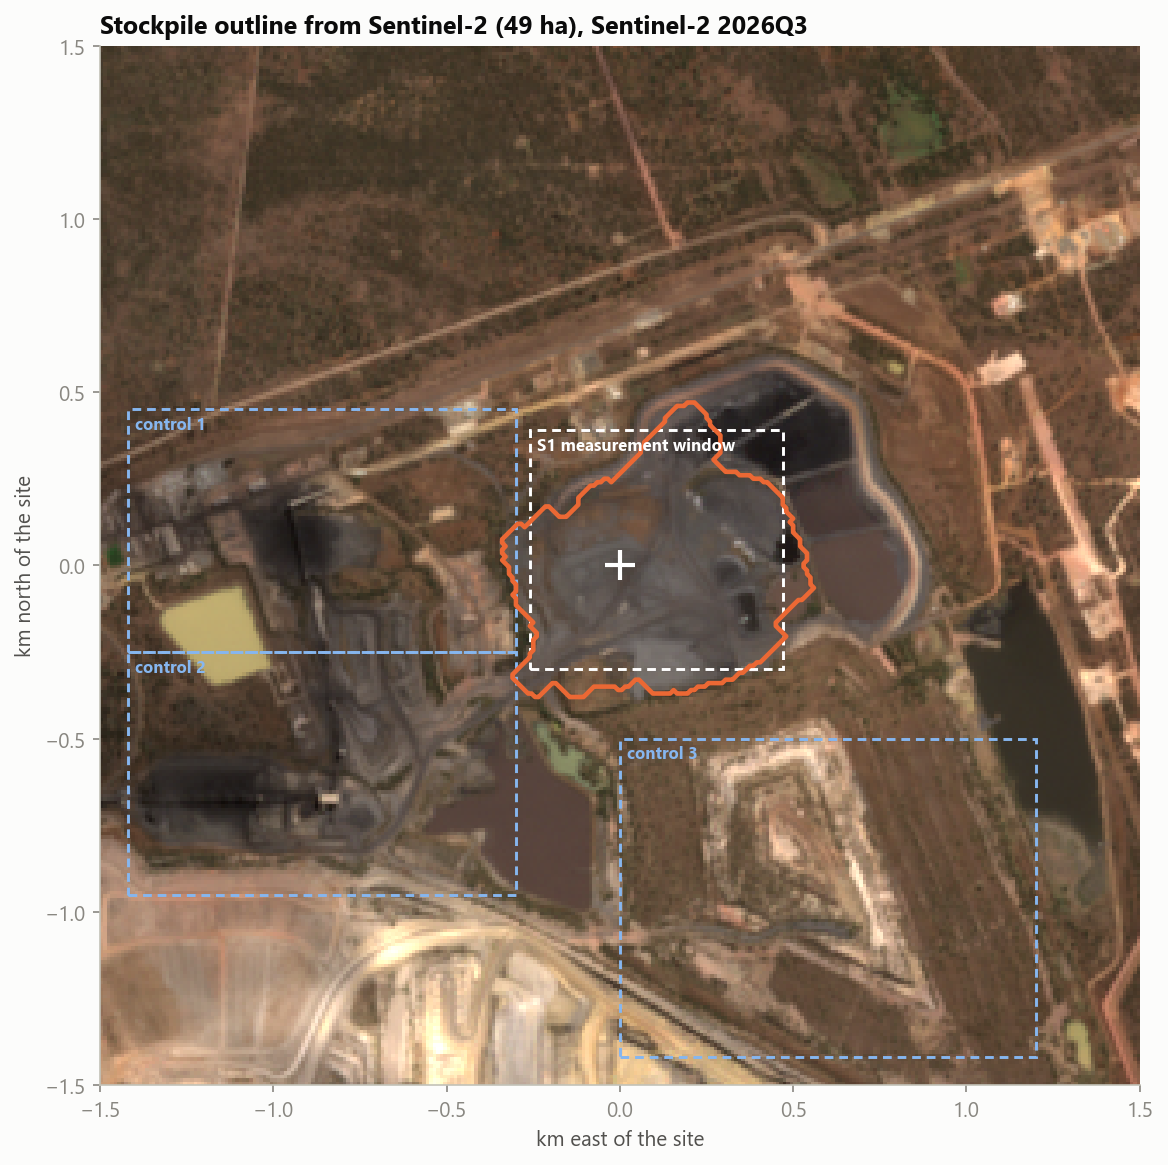

In [2]:
from IPython.display import Image, display
display(Image(filename='out/01_map.png', width=1050))

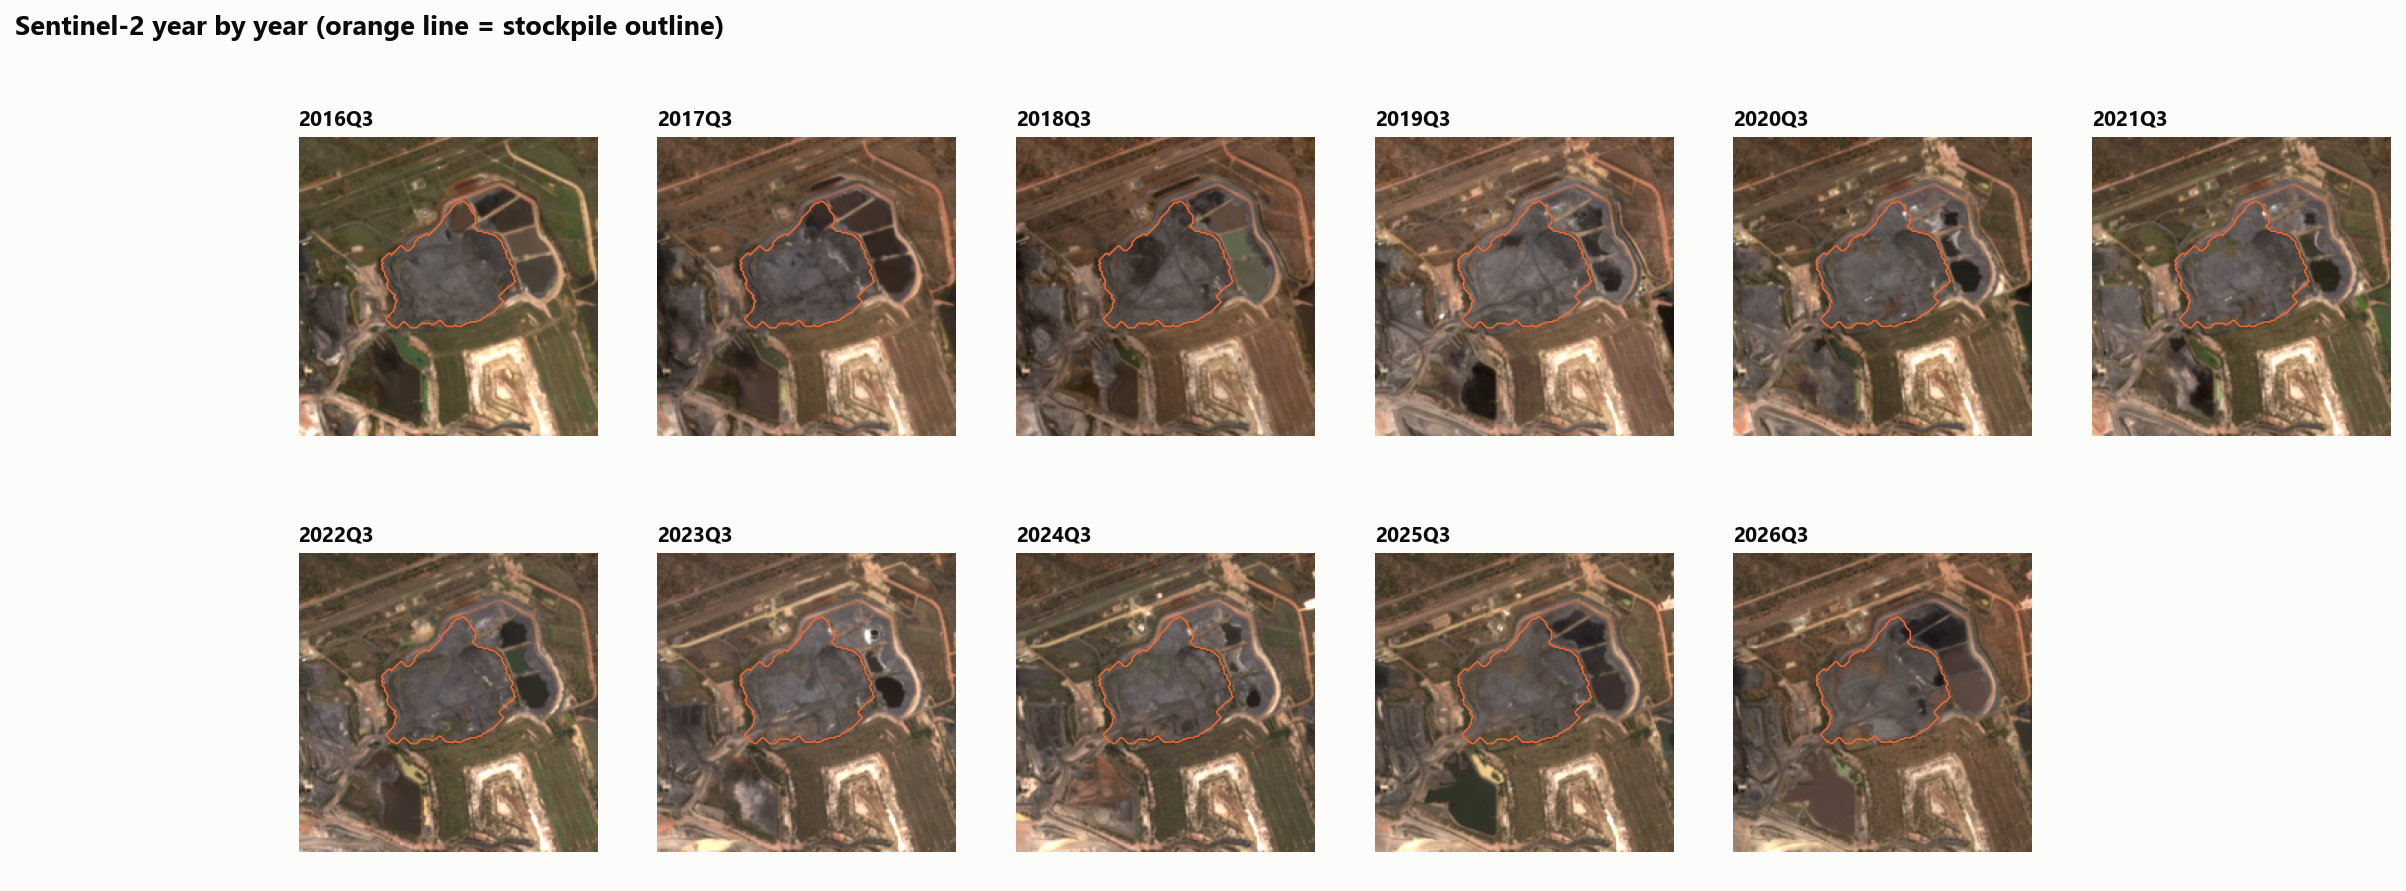

In [3]:
from IPython.display import Image, display
display(Image(filename='out/05_s2_mosaic.png', width=1050))

## 2. Measured history: three DEMs
In February 2000 this was flat ground. Stockpile height = epoch DEM − SRTM, after vertical alignment on stable ground.

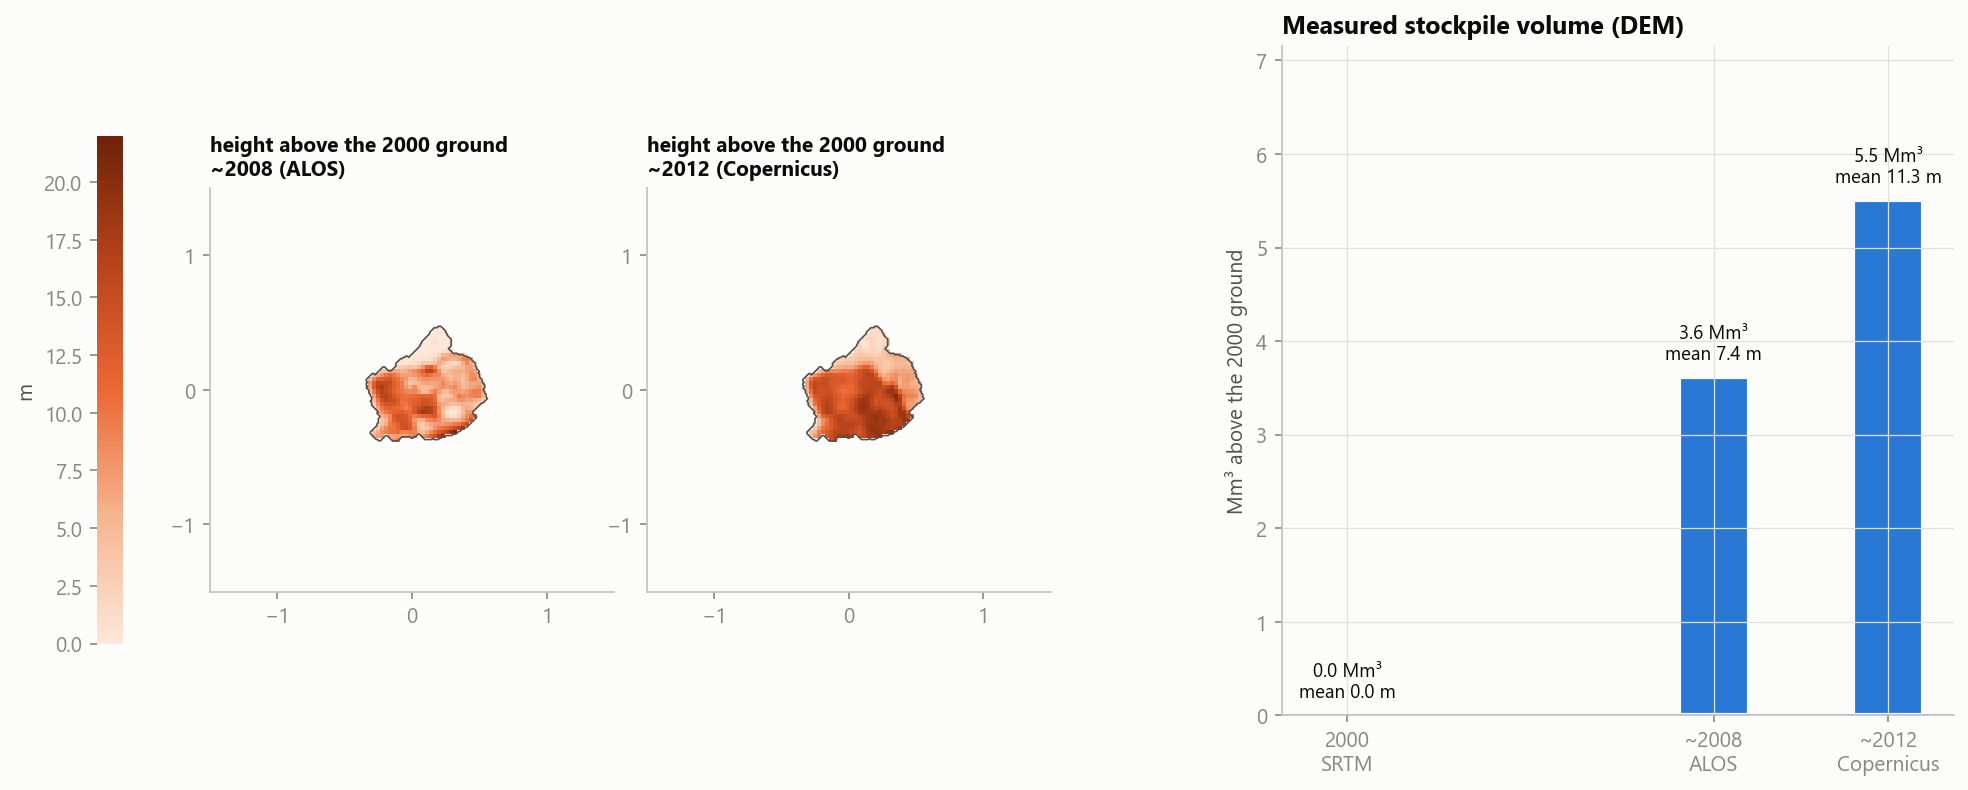

In [4]:
from IPython.display import Image, display
display(Image(filename='out/02_dem_history.png', width=1050))

## 3. Sentinel-1: height after 2016 (radargrammetry from geocoding)
RTC scenes are geocoded with Copernicus DEM (~2012). A surface Δh higher than the DEM is closer to the satellite than geocoding assumes, so it appears shifted towards the satellite by **Δh · cot θ** (θ from the scene annotation). The shift is measured:

* with **normalised cross-correlation** within ±60 m and a parabolic sub-pixel peak,
* in a **network of pairs** 1–4 quarters apart (the stockpile texture changes after dumping, so a comparison with 2016 loses correlation), solved by least squares as in SBAS,
* **relative to the median of three stable windows** — all windows shift together by several metres at times (changes in Sentinel-1 orbit processing, not terrain); the median is robust to one window that changes.

Noise = spread of the control windows. Sensitivity checked by **injecting** a known height step into real images (±3 m, +6 m): it comes back with the right sign and no false signal before the step; the under-estimate (the window also holds static edges) is calibrated.

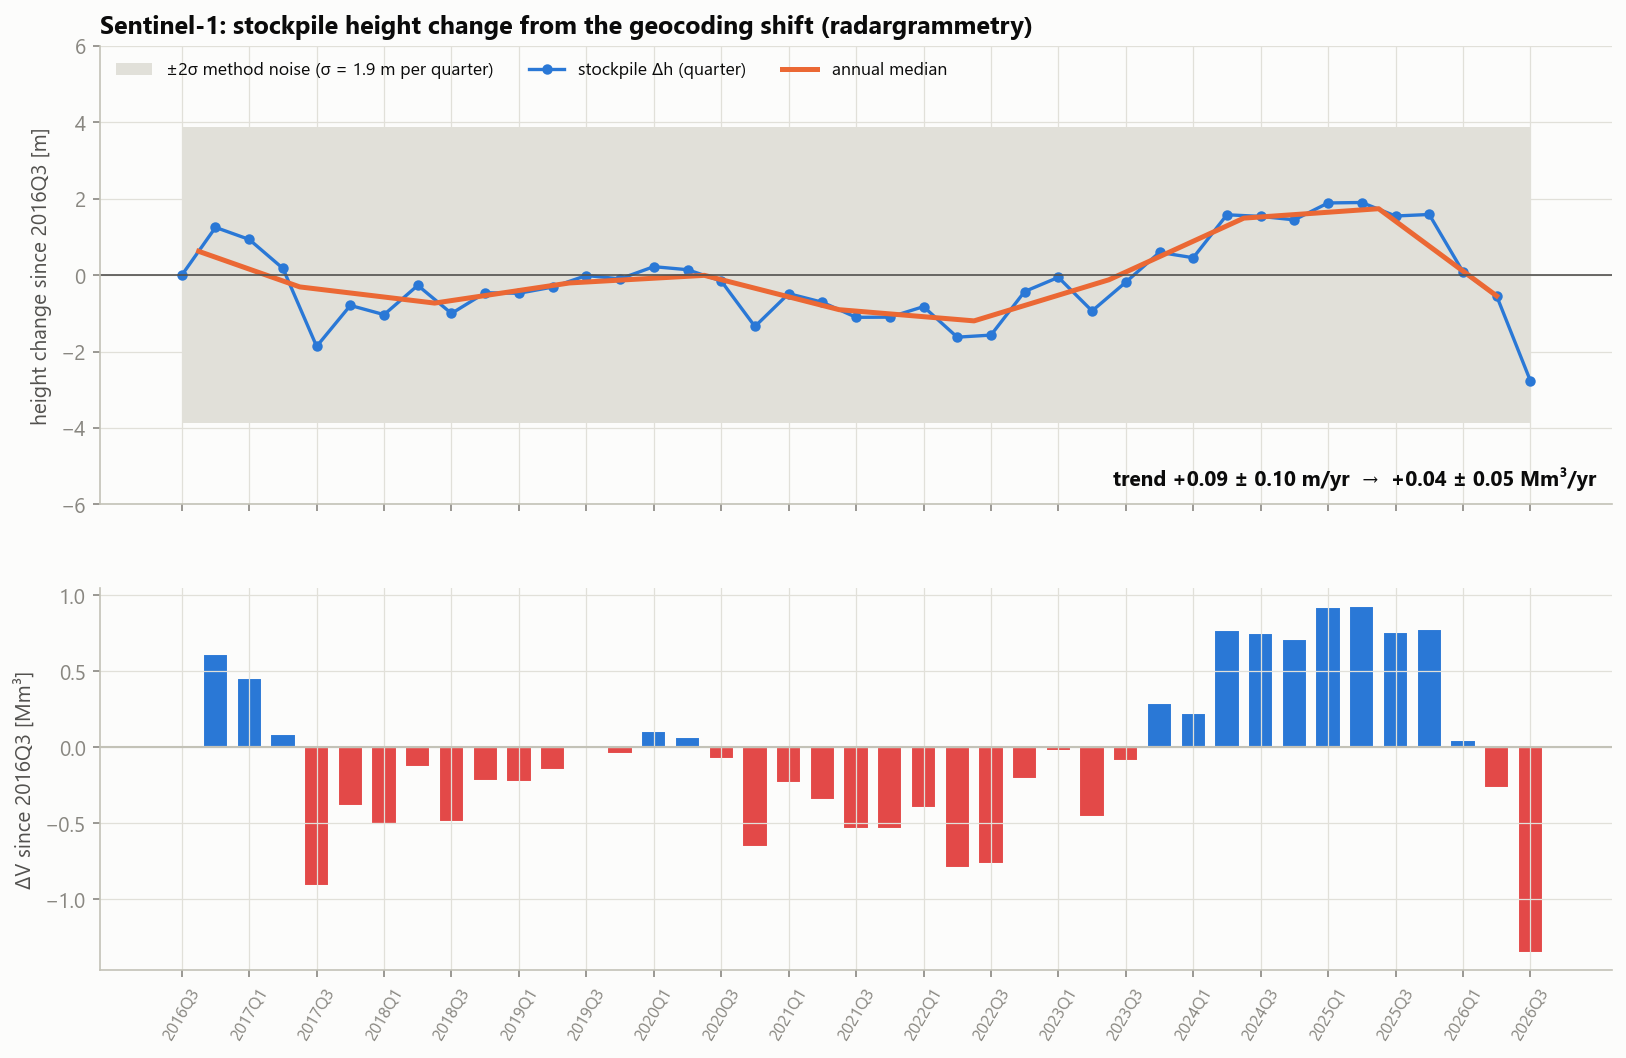

In [5]:
from IPython.display import Image, display
display(Image(filename='out/03_s1_height.png', width=1050))

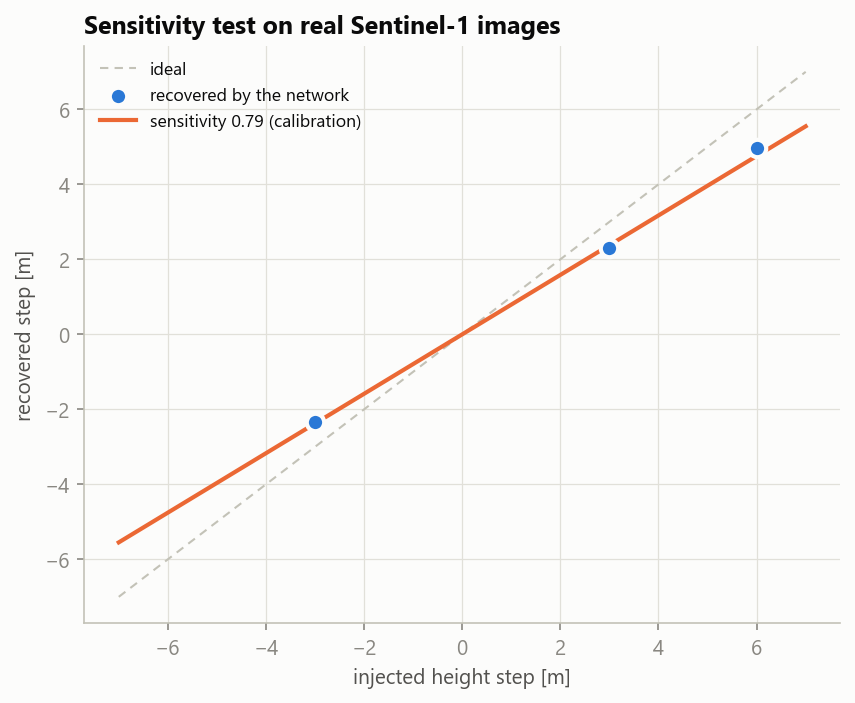

In [6]:
from IPython.display import Image, display
display(Image(filename='out/06_sensitivity_test.png', width=1050))

## 4. Surface cover and activity

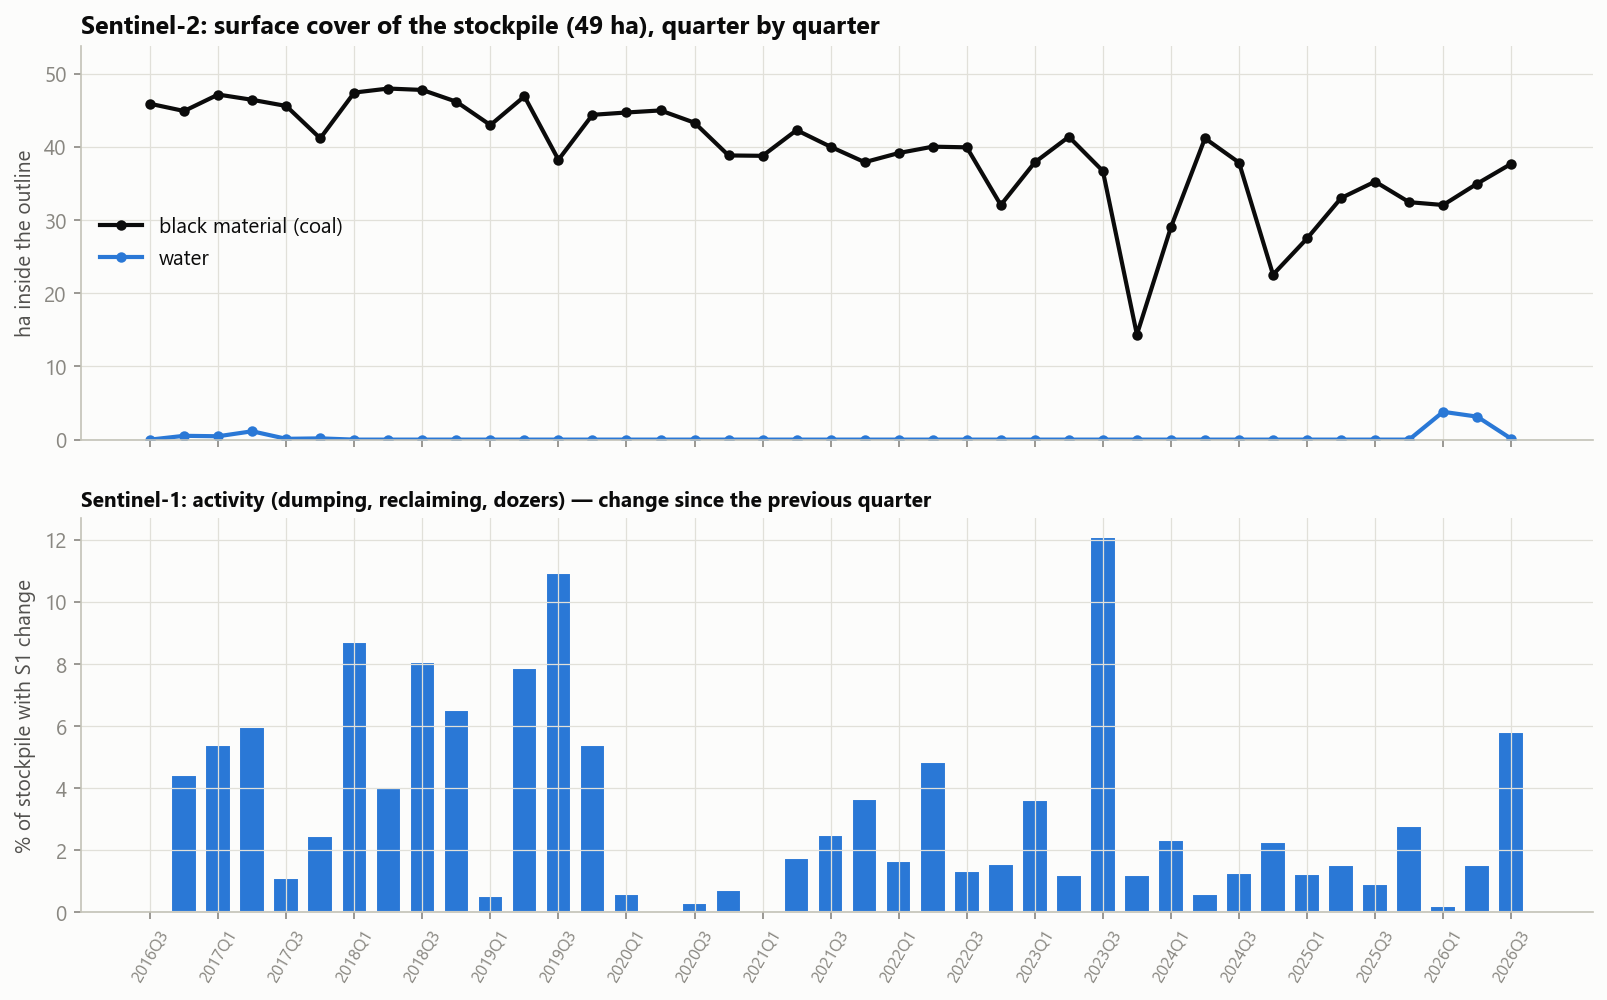

In [7]:
from IPython.display import Image, display
display(Image(filename='out/04_cover_activity.png', width=1050))

In [8]:
pd.read_csv('out/stockpile_quarterly.csv').round(2)

,quarter,n_scenes,coal_ha,water_ha,brightness,dh_m,dv_Mm3,dv_sigma_Mm3,activity_pct,year
0,2016Q3,7,45.88,0.00,0.06,-0.00,-0.00,0.95,NaN,2016
1,2016Q4,4,44.89,0.52,0.07,1.25,0.61,0.95,4.42,2016
2,2017Q1,3,47.14,0.46,0.06,0.94,0.46,0.95,5.38,2017
3,2017Q2,5,46.42,1.14,0.05,0.18,0.09,0.95,5.97,2017
4,2017Q3,16,45.58,0.11,0.06,-1.86,-0.91,0.95,1.08,2017
5,2017Q4,6,41.16,0.17,0.07,-0.79,-0.39,0.95,2.45,2017
6,2018Q1,7,47.41,0.00,0.06,-1.03,-0.51,0.95,8.71,2018
7,2018Q2,13,47.96,0.00,0.05,-0.27,-0.13,0.95,4.01,2018
8,2018Q3,17,47.77,0.00,0.05,-1.00,-0.49,0.95,8.06,2018
9,2018Q4,12,46.16,0.00,0.07,-0.46,-0.22,0.95,6.50,2018


## 5. 3D
`out/stockpile_3d.html` — one file (three.js), opens from disk. Frames: 2000 → ~2008 → ~2012 (DEM) and the quarters since 2016Q3 (Copernicus DEM + Δh from S1, S2 texture). ←/→, space.

## Limitations
* **2012 → 2016 gap** — no free height measurement covers it; the S1 series is relative (from its first quarter), not absolute.
* S1 measures the **mean** height change in the stockpile window; reworking inside it (reclaimed here, dumped there) cancels out.
* Noise ~2 m per quarter → a detectable annual change of ~2 m, i.e. ~1 Mm³ on this footprint.
* The last quarters of the series have fewer pairs in the network, so they are less constrained.
* Optical data cannot tell saleable coal from coal rejects — both are black.